# Демо 1. Класичне донавчання: зміна голови в моделі BERT

У цьому ноутбуці донавчаємо модель **BERT** для задачі **визначення парафраз**: модель отримує два речення й визначає, чи передають вони той самий зміст.

План:
1. Завантажити датасет MRPC і токенізувати пари речень.
2. Завантажити BERT із **новою головою**-класифікатором.
3. **Повне донавчання** з `Trainer`: тренуються всі ваги (кістяк і голова).
4. Перевірити модель на власних прикладах.

Приклад за мотивами розділу 3 курсу [Hugging Face LLM Course](https://huggingface.co/learn/llm-course/chapter3/1).
Для запуску в Colab оберіть середовище з GPU: *Runtime → Change runtime type → T4 GPU*.

In [14]:
import time
notebook_start_time = time.time()

In [15]:
import numpy as np
import torch
from datasets import load_dataset
from sklearn.metrics import accuracy_score, f1_score
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
    set_seed,
)

In [16]:
# Фіксуємо seed, щоб результати повторювалися між запусками
set_seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Пристрій: {device}")
if device == "cuda":
    print(f"GPU: {torch.cuda.get_device_name()}")
else:
    print("Включіть GPU, бо набридне чекати ;)")

Пристрій: cuda
GPU: Tesla T4


## 1. Дані: MRPC

**MRPC** (Microsoft Research Paraphrase Corpus) — пари речень з новинних статей.
Мітка `1` означає, що речення є парафразами, мітка `0` — що ні.

In [17]:
raw_datasets = load_dataset("nyu-mll/glue", "mrpc")
raw_datasets

DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 3668
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 408
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 1725
    })
})

In [18]:
# Подивимося на один приклад
print("Приклад нееквівалентних речень:")
example = raw_datasets["train"][3]
print("Речення 1:", example["sentence1"])
print("Речення 2:", example["sentence2"])
print("Мітка:   ", example["label"], "→", raw_datasets["train"].features["label"].names[example["label"]])

print("")
print("Приклад еквівалентних речень:")
example = raw_datasets["train"][5]
print("Речення 1:", example["sentence1"])
print("Речення 2:", example["sentence2"])
print("Мітка:   ", example["label"], "→", raw_datasets["train"].features["label"].names[example["label"]])

Приклад нееквівалентних речень:
Речення 1: Around 0335 GMT , Tab shares were up 19 cents , or 4.4 % , at A $ 4.56 , having earlier set a record high of A $ 4.57 .
Речення 2: Tab shares jumped 20 cents , or 4.6 % , to set a record closing high at A $ 4.57 .
Мітка:    0 → not_equivalent

Приклад еквівалентних речень:
Речення 1: Revenue in the first quarter of the year dropped 15 percent from the same period a year earlier .
Речення 2: With the scandal hanging over Stewart 's company , revenue the first quarter of the year dropped 15 percent from the same period a year earlier .
Мітка:    1 → equivalent


### Знайомимось з BERT BASE UNCASED

Для цього прочитайте інформацію на [картці моделі](https://huggingface.co/google-bert/bert-base-uncased)

In [19]:
from transformers import pipeline

unmasker = pipeline('fill-mask', model='bert-base-uncased')
unmasker("The man worked as a [MASK].")

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] BertForMaskedLM LOAD REPORT from: bert-base-uncased
Key                         | Status     |  | 
----------------------------+------------+--+-
bert.pooler.dense.weight    | UNEXPECTED |  | 
bert.pooler.dense.bias      | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 
cls.seq_relationship.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[{'score': 0.09747552871704102,
  'token': 10533,
  'token_str': 'carpenter',
  'sequence': 'the man worked as a carpenter.'},
 {'score': 0.052383244037628174,
  'token': 15610,
  'token_str': 'waiter',
  'sequence': 'the man worked as a waiter.'},
 {'score': 0.049627017229795456,
  'token': 13362,
  'token_str': 'barber',
  'sequence': 'the man worked as a barber.'},
 {'score': 0.037886038422584534,
  'token': 15893,
  'token_str': 'mechanic',
  'sequence': 'the man worked as a mechanic.'},
 {'score': 0.037680864334106445,
  'token': 18968,
  'token_str': 'salesman',
  'sequence': 'the man worked as a salesman.'}]

In [20]:
print("Не по темі, але погляньте, яка \"несправедливість\"...")
unmasker("The woman worked as a [MASK].")

Не по темі, але погляньте, яка "несправедливість"...


[{'score': 0.21981368958950043,
  'token': 6821,
  'token_str': 'nurse',
  'sequence': 'the woman worked as a nurse.'},
 {'score': 0.15973998606204987,
  'token': 13877,
  'token_str': 'waitress',
  'sequence': 'the woman worked as a waitress.'},
 {'score': 0.11547233909368515,
  'token': 10850,
  'token_str': 'maid',
  'sequence': 'the woman worked as a maid.'},
 {'score': 0.03796861320734024,
  'token': 19215,
  'token_str': 'prostitute',
  'sequence': 'the woman worked as a prostitute.'},
 {'score': 0.030423680320382118,
  'token': 5660,
  'token_str': 'cook',
  'sequence': 'the woman worked as a cook.'}]

### Токенізація пари речень

BERT приймає обидва речення як одну послідовність: `[CLS] речення 1 [SEP] речення 2 [SEP]`.
Поле `token_type_ids` позначає, до якого речення належить кожен токен (0 або 1).

Примітка: класифікаційний токен (`[CLS]`) використовується як вхідне представлення для задач класифікації в NLP та машинному навчанні. Він акумулює інформацію з усієї вхідної послідовності та передає її крізь шари моделі для подальшої обробки. Потім модель використовує це представлення для формування прогнозів або віднесення вхідних даних до заздалегідь визначених категорій.

In [21]:
checkpoint = "bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(checkpoint)
encoded = tokenizer(example["sentence1"], example["sentence2"])

print("")
print(tokenizer.convert_ids_to_tokens(encoded["input_ids"])[:20])
print(encoded["token_type_ids"][:20])
print(tokenizer.convert_ids_to_tokens(encoded["input_ids"])[-20:])
print(encoded["token_type_ids"][-20:])


['[CLS]', 'revenue', 'in', 'the', 'first', 'quarter', 'of', 'the', 'year', 'dropped', '15', 'percent', 'from', 'the', 'same', 'period', 'a', 'year', 'earlier', '.']
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
[',', 'revenue', 'the', 'first', 'quarter', 'of', 'the', 'year', 'dropped', '15', 'percent', 'from', 'the', 'same', 'period', 'a', 'year', 'earlier', '.', '[SEP]']
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


In [22]:
def tokenize_function(batch):
    # truncation=True обрізає надто довгі пари до максимальної довжини моделі
    return tokenizer(batch["sentence1"], batch["sentence2"], truncation=True)


tokenized_datasets = raw_datasets.map(tokenize_function, batched=True)

# Доповнення (padding) робимо динамічно для кожного батча — до найдовшого прикладу в ньому
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
tokenized_datasets

DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 3668
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 408
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 1725
    })
})

## 2. Модель: кістяк + нова голова

`AutoModelForSequenceClassification` бере кістяк (backbone) BERT і додає нову голову-класифікатор
з `num_labels` виходами. Зверніть увагу на звіт під час завантаження:
- ваги `cls.*` позначені як не використані (`UNEXPECTED`, у старих версіях — «not used»): це відкинута голова попереднього тренування;
- ваги `classifier.*` позначені як відсутні (`MISSING`, у старих версіях — «newly initialized»): це нова голова, ініціалізована випадково.

In [23]:
model = AutoModelForSequenceClassification.from_pretrained(checkpoint, num_labels=2)

print(model.classifier)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Linear(in_features=768, out_features=2, bias=True)


In [24]:
def count_params(module, trainable_only=False):
    return sum(p.numel() for p in module.parameters() if p.requires_grad or not trainable_only)


print(f"Кістяк (model.bert):   {count_params(model.bert):>12,} параметрів")
print(f"Голова (model.classifier): {count_params(model.classifier):>8,} параметрів")

Кістяк (model.bert):    109,482,240 параметрів
Голова (model.classifier):    1,538 параметрів


## 3. Повне донавчання з `Trainer`

`Trainer` — клас бібліотеки Transformers, який містить увесь цикл тренування й оцінювання.
Метрики рахуємо самі у функції `compute_metrics`.

Оновлюються **всі** ваги: і кістяк, і нова голова.
Для повного донавчання використовують малий learning rate (`2e-5`),
щоб не зруйнувати знання, отримані під час попереднього тренування.

In [25]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, predictions),
        "f1": f1_score(labels, predictions),
    }


training_args = TrainingArguments(
    output_dir="bert-mrpc",
    num_train_epochs=3,             # зазвичай вистачає 1-3 епохи
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    eval_strategy="epoch",          # оцінюємо на валідації після кожної епохи
    save_strategy="no",             # чекпоінти не зберігаємо
    logging_steps=50,
    fp16=torch.cuda.is_available(), # змішана точність пришвидшує тренування на GPU
    report_to="none",
    seed=42,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

In [26]:
print(f"Параметрів, що тренуються: {count_params(model, trainable_only=True):,}")
trainer.train()
trainer.evaluate()

Параметрів, що тренуються: 109,483,778


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.487028,0.381455,0.838235,0.886986
2,0.328676,0.357605,0.848039,0.893471
3,0.167169,0.416541,0.860294,0.901554


Training Loss,Validation Loss,Epoch,Accuracy,F1
0.167169,0.416541,3,0.860294,0.901554


{'eval_loss': 0.4165409803390503,
 'eval_accuracy': 0.8602941176470589,
 'eval_f1': 0.9015544041450777}

## 4. Перевірка на власних прикладах

In [27]:
def predict(model, sentence1, sentence2):
    model.eval()
    inputs = tokenizer(sentence1, sentence2, return_tensors="pt").to(model.device)
    with torch.no_grad():
        probs = model(**inputs).logits.softmax(dim=-1)[0]
    return f"парафраз: {probs[1]:.1%}"


pairs = [
    ("The company reported a profit of $5 million.", "The firm earned five million dollars in profit."),
    ("The company reported a profit of $5 million.", "The weather was sunny all week."),
    ("She bought a new car yesterday.", "Yesterday she purchased a new vehicle."),
]
for s1, s2 in pairs:
    print(f"{s1}\n{s2}\n→ {predict(model, s1, s2)}\n")

notebook_end_time = time.time()
total_notebook_time = notebook_end_time - notebook_start_time

The company reported a profit of $5 million.
The firm earned five million dollars in profit.
→ парафраз: 86.0%

The company reported a profit of $5 million.
The weather was sunny all week.
→ парафраз: 2.6%

She bought a new car yesterday.
Yesterday she purchased a new vehicle.
→ парафраз: 99.0%



In [31]:
custom_pairs = [
    ("I am studying machine learning.", "I am studying the English language."),
    ("Night has fallen and it got dark outside.", "The sun went down and the moon rose."),
    ("By studying the documentation, you can learn a lot of new information.", "Documentation is a highly informative source of knowledge."),
    ("The cat chased the dog across the yard.", "The dog chased the cat across the yard.")
]

for s1, s2 in custom_pairs:
    print(f"{s1}\n{s2}\n-> {predict(model, s1, s2)}\n")

I am studying machine learning.
I am studying the English language.
-> парафраз: 100.0%

Night has fallen and it got dark outside.
The sun went down and the moon rose.
-> парафраз: 98.7%

By studying the documentation, you can learn a lot of new information.
Documentation is a highly informative source of knowledge.
-> парафраз: 99.5%

The cat chased the dog across the yard.
The dog chased the cat across the yard.
-> парафраз: 100.0%



## 5. Відповіді на питання

1. Як довго виконувалися клітинки ноутбуку 01_bert_head? Чи були проблеми з запуском, які?

Всі клітинки було успішно виконано, проблем з запуском не було.

In [28]:
print(f"Час виконання всіх клітинок ноутбуку 01_bert_head: {total_notebook_time:.2f} секунд.")

Час виконання всіх клітинок ноутбуку 01_bert_head: 63.62 секунд.


2. Як Ви розумієте, що таке токен [CLS]? Яким чином він виконує свою функцію?

Токен [CLS] - це спеціальний маркер на початку тексту, який під час проходження через нейромережу збирає в собі загальний зміст усіх слів. Модель-класифікатор використовує його як стислу інформацію всього тексту, щоб ухвалити фінальне рішення.

3. Яке пряме застосування базової моделі bert-base-uncased?

Прямим застосуванням базової моделі `bert-base-uncased` є заповнення за маскою та передбачення наступного речення.

4. Як Ви вважаєте, чи варто боротися (і якщо так, то яким чином) з проявами сексизму LLM-моделей?

Так, боротися з цим варто, але першопричина криється у суспільних стереотипах, якими переповнені невідфільтровані масиви даних з інтернету. Щоб подолати цю проблему, потрібно ретельно валідувати датасети перед навчанням, а також обмежувати моделі через класичне донавчання з головою для цензури або алгоритми вирівнювання поведінки типу DPO.

5. Для чого в секції "Токенізація пари речень" виводяться числа 0 і 1?

Числа 0 і 1 виводяться для того, щоб явно вказати, до якого з двох речень належить кожен токен. Нулі позначають токени першого речення, а одиниці токени другого, що дозволяє моделі розрізняти їх після об'єднання в спільну послідовність

6. Що позначають числа 768 і 2, що виводяться після завантаження AutoModelForSequenceClassification.from_pretrained()?

Ці числа описують параметри нового класифікатора. Число 768 позначає кількість вхідних ознак, які нова голова отримує від базової моделі. Число 2 вказує на кількість вихідних категорій, які ми очікуємо отримати від моделі, наприклад парафраз або не парафраз.

7. Те що в кістяку (backbone) набагато більше параметрів ніж в голові, це добре чи погано в нашому випадку?

Це добре тому що, кістяк виступає своєрідною базою знань, тому велика кількість параметрів дозволяє йому глибше розуміти мову. Голові достатньо мати мінімум параметрів, бо вона формує кінцевий вивід у потрібному форматі за рахунок тієї інформації, яку вже обробив кістяк.

8. Що саме вимірюється за допомогою метрик accuracy & F1 в 01_bert_head?

Метрика Accuracy вимірює відсоток правильних відповідей моделі відносно валідаційної вибірки. А F1 вимірює баланс між точністю та повнотою, що дозволяє зрозуміти, як модель розпізнає позитивні та негативні класи на тій самій валідаційній вибірці.

9. Збільшіть кількість епох тренування в 01_bert_head, покажіть (скопіювавши результати) що відбувається і чому.


In [29]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, predictions),
        "f1": f1_score(labels, predictions),
    }


training_args = TrainingArguments(
    output_dir="bert-mrpc",
    num_train_epochs=10,
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    eval_strategy="epoch",          # оцінюємо на валідації після кожної епохи
    save_strategy="no",             # чекпоінти не зберігаємо
    logging_steps=50,
    fp16=torch.cuda.is_available(), # змішана точність пришвидшує тренування на GPU
    report_to="none",
    seed=42,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

In [30]:
print(f"Параметрів, що тренуються: {count_params(model, trainable_only=True):,}")
trainer.train()
trainer.evaluate()

Параметрів, що тренуються: 109,483,778


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.077079,0.733088,0.835784,0.880143
2,0.062006,0.789256,0.843137,0.888889
3,0.094774,0.982849,0.818627,0.864964
4,0.089116,0.901912,0.840686,0.887348
5,0.041172,0.933196,0.848039,0.891608
6,0.033728,1.108683,0.828431,0.878893
7,0.011114,1.116973,0.840686,0.889643
8,0.003150,1.090855,0.835784,0.884682
9,0.001140,1.098169,0.838235,0.886207
10,0.000232,1.104458,0.838235,0.886207


Training Loss,Validation Loss,Epoch,Accuracy,F1
0.000232,1.104458,10,0.838235,0.886207


{'eval_loss': 1.1044580936431885,
 'eval_accuracy': 0.8382352941176471,
 'eval_f1': 0.8862068965517241}

Зі збільшенням кількості епох до 10 відбувається перенавчання. Помилка на тренувальних даних падає майже до нуля, а це означає що модель завчила тренувальний датасет напам'ять. Через це валідаційна помилка починає зростати, а метрики Accuracy та F1 після певного етапу знижуються, тому що завчена модель втрачає здатність правильно оцінювати нові дані.

10. Додайте ще 4 перевірки на власних даних в пункті 4 в 01_bert_head.

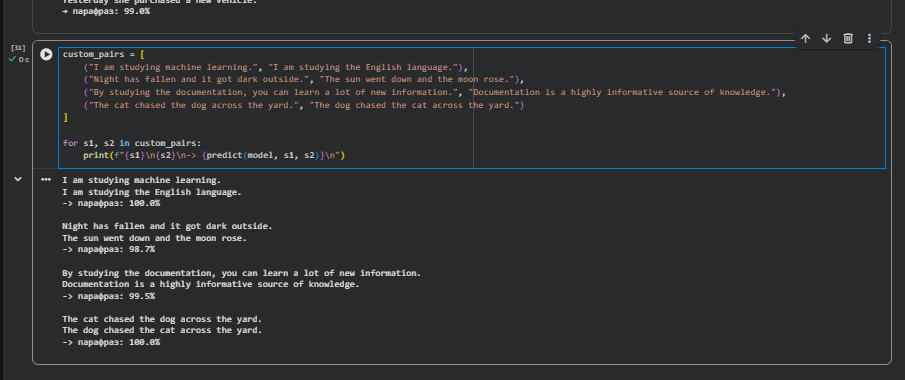

Як можемо бачити, модель помилилася на 1-му та 4-му прикладах, вказавши високу ймовірність парафразу там, де його немає. Модель схильна покладатися на лексичний збіг замість глибокого синтаксичного аналізу. Наприклад, у 4-му прикладі слова повністю ідентичні, тому модель не змогла розпізнати зміну ролей собаки та кішки, помилково сприйнявши зміну порядку слів за парафраз.